# 1. Setup and Depencencies


In [54]:
%cd /content

!git clone https://github.com/ddawnkhoa/Eclat-Frequent-Itemset-Mining.git

/content
fatal: destination path 'Eclat-Frequent-Itemset-Mining' already exists and is not an empty directory.


In [55]:
import os
import subprocess

PROJECT_DIR = "/content/Eclat-Frequent-Itemset-Mining"

os.chdir(PROJECT_DIR)

result = subprocess.run(
    ["git", "pull"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError("Git pull failed.")

print("Repository updated successfully.")


Updating 36716ae..a68cb60
Fast-forward
 Group_5/docs/Report.pdf         | Bin 0 -> 1691427 bytes
 Group_5/tests/runtests.jl       |  33 +++++++++++++++++++++++++++++++++
 Group_5/tests/test_benchmark.jl |   0
 Group_5/tests/test_io.jl        |   2 +-
 4 files changed, 34 insertions(+), 1 deletion(-)
 create mode 100644 Group_5/docs/Report.pdf
 create mode 100644 Group_5/tests/runtests.jl
 delete mode 100644 Group_5/tests/test_benchmark.jl

From https://github.com/ddawnkhoa/Eclat-Frequent-Itemset-Mining
   36716ae..a68cb60  main       -> origin/main

Repository updated successfully.


In [32]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path("/content/Eclat-Frequent-Itemset-Mining/Group_5")

DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "docs" / "figures"
TESTS_DIR = PROJECT_ROOT / "tests"

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

In [33]:
import os
import shutil
import subprocess

# Cài Julia nếu runtime Colab chưa có
if shutil.which("julia") is None:
    subprocess.run(
        "curl -fsSL https://install.julialang.org | sh -s -- -y",
        shell=True,
        check=True
    )

# Thêm Julia vào PATH của notebook
os.environ["PATH"] += os.pathsep + str(Path.home() / ".juliaup" / "bin")

JULIA = shutil.which("julia")
print(subprocess.check_output([JULIA, "--version"], text=True))

# Cài dependencies theo Project.toml
if (PROJECT_ROOT / "Project.toml").exists():
    subprocess.run(
        [JULIA, f"--project={PROJECT_ROOT}", "-e",
         "using Pkg; Pkg.instantiate()"],
        check=True
    )
    print("Julia dependencies installed.")
else:
    print("Không tìm thấy Project.toml trong project.")

julia version 1.12.6

Julia dependencies installed.


In [34]:
main_file = PROJECT_ROOT / "src" / "main.jl"

print("Main file exists:", main_file.exists())

if main_file.exists():
    subprocess.run(
        [JULIA, f"--project={PROJECT_ROOT}", str(main_file)],
        cwd=PROJECT_ROOT,
        check=False
    )

Main file exists: True


Unit Tests:

In [56]:
import os
import subprocess

# Navigate to the project root
PROJECT_DIR = "/content/Eclat-Frequent-Itemset-Mining/Group_5"
os.chdir(PROJECT_DIR)

print("Project directory:", os.getcwd())
print("\nRunning Julia unit tests...\n")

result = subprocess.run(
    ["julia", "--project=.", "tests/runtests.jl"],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr)

if result.returncode == 0:
    print("\nUNIT TESTS: PASSED")
else:
    print("\nUNIT TESTS: FAILED")
    raise RuntimeError("Some unit tests did not pass.")

Project directory: /content/Eclat-Frequent-Itemset-Mining/Group_5

Running Julia unit tests...


========== ECLAT UNIT TESTS ==========


Running test_correctness.jl ...

Running test_bitvector.jl ...

Testing: normal.txt
Vector itemsets: 7
BitVector itemsets: 7
Result: PASS

Testing: empty.txt
Vector itemsets: 0
BitVector itemsets: 0
Result: PASS

Testing: singleton_only.txt
Vector itemsets: 1
BitVector itemsets: 1
Result: PASS

Testing: no_frequent.txt
Vector itemsets: 0
BitVector itemsets: 0
Result: PASS

Testing: multi_itemset.txt
Vector itemsets: 14
BitVector itemsets: 14
Result: PASS

Running test_optimization.jl ...

Dataset: normal.txt
Correctness: PASS
Frequent itemsets: 7
Vector runtime: 0.000032 s
BitVector runtime: 0.000042 s
Speedup: 0.780x
Vector allocated: 0.0036 MB
BitVector allocated: 0.0037 MB
Memory ratio: 0.983x

Dataset: empty.txt
Correctness: PASS
Frequent itemsets: 0
Vector runtime: 0.000003 s
BitVector runtime: 0.000003 s
Speedup: 1.020x
Vector allocated: 0.0001

# 2. Eclat Demo on Toy Datasets
The demo illustrates how the algorithm transforms a transaction database into a vertical representation, calculates itemset support using transaction ID intersections, and identifies frequent itemsets based on a minimum support threshold

In [35]:
toy_file = DATA_DIR / "toy_demo.txt"
toy_output = DATA_DIR / "toy_demo_result.txt"

DATA_DIR.mkdir(parents=True, exist_ok=True)

toy_file.write_text(
    "1 2 3\n"
    "1 2\n"
    "1 3\n"
    "2 3\n"
    "1 2 3\n",
    encoding="utf-8"
)

minsup = 2

subprocess.run(
    [
        JULIA,
        f"--project={PROJECT_ROOT}",
        str(PROJECT_ROOT / "src" / "main.jl"),
        str(toy_file),
        str(minsup),
        str(toy_output)
    ],
    cwd=PROJECT_ROOT,
    check=True
)

print("Toy dataset:")
print(toy_file.read_text())

print("Eclat output:")
print(toy_output.read_text())

Toy dataset:
1 2 3
1 2
1 3
2 3
1 2 3

Eclat output:
1 #SUP: 4
1 2 #SUP: 3
1 2 3 #SUP: 2
1 3 #SUP: 3
2 #SUP: 4
2 3 #SUP: 3
3 #SUP: 4



# 3. SPMF Correctness
This experiment evaluates the correctness of the implemented Eclat algorithms by comparing their frequent itemsets and support counts with the results generated by SPMF on the toy datasets.

In [36]:
import subprocess
import pandas as pd

TOY_DIR = DATA_DIR / "toy"
TOY_OUTPUT_DIR = TOY_DIR / "outputs"
COMPARE_SCRIPT = PROJECT_ROOT / "tests" / "compare_spmf.jl"

# SPMF không sinh itemset cho dataset rỗng
empty_spmf = TOY_OUTPUT_DIR / "empty_spmf.txt"
empty_spmf.write_text("", encoding="utf-8")

datasets = [
    ("normal", 2),
    ("empty", 1),
    ("singleton_only", 3),
    ("no_frequent", 3),
    ("multi_itemset", 2),
]

comparison_results = []

for name, minsup in datasets:
    julia_file = TOY_OUTPUT_DIR / f"{name}_julia.txt"
    spmf_file = TOY_OUTPUT_DIR / f"{name}_spmf.txt"

    result = subprocess.run(
        [
            JULIA,
            f"--project={PROJECT_ROOT}",
            str(COMPARE_SCRIPT),
            str(julia_file),
            str(spmf_file),
        ],
        cwd=PROJECT_ROOT,
        capture_output=True,
        text=True,
    )

    output = result.stdout + result.stderr
    passed = "Exact match: PASS" in output

    comparison_results.append({
        "Dataset": name,
        "MinSup": minsup,
        "Julia Itemsets": (
            int(line.split(":")[1].strip())
            for line in output.splitlines()
            if line.startswith("Julia itemsets:")
        ),
        "SPMF Itemsets": (
            int(line.split(":")[1].strip())
            for line in output.splitlines()
            if line.startswith("SPMF itemsets:")
        ),
        "Exact Match": "PASS" if passed else "FAIL",
    })

# Chuyển dữ liệu về bảng
for row in comparison_results:
    for key in ["Julia Itemsets", "SPMF Itemsets"]:
        value = row[key]
        if not isinstance(value, int):
            row[key] = next(value)

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,Dataset,MinSup,Julia Itemsets,SPMF Itemsets,Exact Match
0,normal,2,7,7,PASS
1,empty,1,0,0,PASS
2,singleton_only,3,1,1,PASS
3,no_frequent,3,0,0,PASS
4,multi_itemset,2,15,15,PASS


# 4. Vector vs BitVector
This experiment compares the Vector and BitVector implementations of the Eclat algorithm.

In [37]:

import subprocess
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

# 1. Tìm script benchmark
candidates = list(PROJECT_ROOT.rglob("test_optimization.jl"))

if not candidates:
    raise FileNotFoundError("Cannot find test_optimization.jl")

if len(candidates) > 1:
    print("Found multiple filea test_optimization.jl:")
    for path in candidates:
        print(path.relative_to(PROJECT_ROOT))
    raise RuntimeError("Cần xác định chính xác script cần chạy.")

script_path = candidates[0]

print("Script:", script_path.relative_to(PROJECT_ROOT))
print("\nRunning optimization benchmark...\n")

result = subprocess.run(
    [JULIA, f"--project={PROJECT_ROOT}", str(script_path)],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print("--- JULIA OUTPUT ---")
print(result.stdout)

if result.stderr:
    print("--- JULIA ERRORS / WARNINGS ---")
    print(result.stderr)

if result.returncode != 0:
    raise RuntimeError(
        f"Benchmark failed. Exit code: {result.returncode}"
    )

# 3. Find optimization csv
optimization_dir = RESULTS_DIR / "optimization"

csv_files = list(optimization_dir.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        f"Không tìm thấy CSV trong {optimization_dir}"
    )

for csv_path in csv_files:
    df = pd.read_csv(csv_path)

    display(Markdown(
        f"### {csv_path.name}"
    ))

    display(df.round(6))

    print("Datasets count:", len(df))
    if "Correctness" in df.columns:
        print(
            "Correctness:",
            f"{(df['Correctness'] == 'PASS').sum()}/{len(df)} PASS"
        )


Script: tests/test_optimization.jl

Đang chạy optimization benchmark...

--- JULIA OUTPUT ---

Dataset: normal.txt
Correctness: PASS
Frequent itemsets: 7
Vector runtime: 0.000033 s
BitVector runtime: 0.000043 s
Speedup: 0.756x
Vector allocated: 0.0036 MB
BitVector allocated: 0.0037 MB
Memory ratio: 0.983x

Dataset: empty.txt
Correctness: PASS
Frequent itemsets: 0
Vector runtime: 0.000003 s
BitVector runtime: 0.000003 s
Speedup: 0.964x
Vector allocated: 0.0001 MB
BitVector allocated: 0.0001 MB
Memory ratio: 1.000x

Dataset: singleton_only.txt
Correctness: PASS
Frequent itemsets: 1
Vector runtime: 0.000021 s
BitVector runtime: 0.000027 s
Speedup: 0.785x
Vector allocated: 0.0007 MB
BitVector allocated: 0.0007 MB
Memory ratio: 1.000x

Dataset: no_frequent.txt
Correctness: PASS
Frequent itemsets: 0
Vector runtime: 0.000003 s
BitVector runtime: 0.000004 s
Speedup: 0.825x
Vector allocated: 0.0001 MB
BitVector allocated: 0.0001 MB
Memory ratio: 1.000x

Dataset: multi_itemset.txt
Correctness: P

### vector_bitvector_optimization.csv

,Dataset,Transactions,MinSup,ItemsetCount,Correctness,VectorRuntimeSec,BitVectorRuntimeSec,Speedup,VectorAllocatedMB,BitVectorAllocatedMB,MemoryRatio
0,normal.txt,5,2,7,PASS,0.000033,0.000043,0.756499,0.003616,0.003677,0.983402
1,empty.txt,0,1,0,PASS,0.000003,0.000003,0.963924,0.000137,0.000137,1.000000
2,singleton_only.txt,4,3,1,PASS,0.000021,0.000027,0.785135,0.000656,0.000656,1.000000
3,no_frequent.txt,3,3,0,PASS,0.000003,0.000004,0.824651,0.000137,0.000137,1.000000
4,multi_itemset.txt,6,2,15,PASS,0.000044,0.000064,0.686822,0.008774,0.008392,1.045455


Datasets count: 5
Correctness: 5/5 PASS


# 5. Benchmark Experiment Results
This section evaluates the performance of the Eclat algorithm using Vector and BitVector representations on larger benchmark datasets.

The evaluation focuses on:
- Correctness
- Runtime performance
- Memory consumption
- Frequent itemset generation
- Scalability
- Transaction length impact

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, Markdown

# Paths
CORRECTNESS_DIR = RESULTS_DIR / "correctness"
RUNTIME_DIR = RESULTS_DIR / "runtime"
MEMORY_DIR = RESULTS_DIR / "memory"
ITEMSET_DIR = RESULTS_DIR / "frequent_itemset_count"
SCALABILITY_DIR = RESULTS_DIR / "scalability"
TRANSACTION_LENGTH_DIR = RESULTS_DIR / "transaction_length"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Load CSV
correctness = pd.read_csv(
    CORRECTNESS_DIR / "benchmark_correctness.csv"
)

runtime_julia = pd.read_csv(
    RUNTIME_DIR / "julia_runtime.csv"
)

runtime_spmf = pd.read_csv(
    RUNTIME_DIR / "spmf_runtime.csv"
)

memory = pd.read_csv(
    MEMORY_DIR / "memory_runtime.csv"
)

itemset_count = pd.read_csv(
    ITEMSET_DIR / "frequent_itemset_count.csv"
)

scalability = pd.read_csv(
    SCALABILITY_DIR / "scalability_runtime.csv"
)

transaction_length = pd.read_csv(
    TRANSACTION_LENGTH_DIR / "transaction_length_runtime.csv"
)

# Dataset order
datasets = ["chess", "mushroom", "retail", "t10i4d100k"]

dataset_labels = {
    "chess": "Chess",
    "mushroom": "Mushroom",
    "retail": "Retail",
    "t10i4d100k": "T10I4D100K"
}

def dataset_key(value):
    return str(value).strip().lower()
# 1. CORRECTNESS

display(Markdown("## 1. Correctness"))

correctness_table = correctness.rename(columns={
    "dataset": "Dataset",
    "minsup_count": "MinSup",
    "julia_itemsets": "Group Itemsets",
    "spmf_itemsets": "SPMF Itemsets",
    "exact_match": "Exact Match",
    "match_percent": "Match (%)"
})

display(correctness_table)

passed = (correctness["exact_match"] == "PASS").sum()
total = len(correctness)

print(f"Overall correctness: {passed}/{total} datasets")
print(f"Exact match rate: {passed / total * 100:.2f}%")

# 2. RUNTIME DATA

display(Markdown("## 2. Runtime by Minimum Support"))

runtime_julia["DatasetKey"] = runtime_julia["Dataset"].apply(dataset_key)
runtime_spmf["DatasetKey"] = runtime_spmf["Dataset"].apply(dataset_key)

runtime_table = pd.concat([
    runtime_julia.assign(Implementation="Group - BitVector"),
    runtime_spmf.assign(Implementation="SPMF")
])

runtime_table = runtime_table.pivot_table(
    index=["Dataset", "MinsupPercent"],
    columns="Implementation",
    values="MedianSec",
    aggfunc="first"
).reset_index()

display(runtime_table.round(4))

# 3. FREQUENT ITEMSET COUNT

display(Markdown("## 3. Frequent Itemset Count"))

itemset_table = itemset_count.pivot_table(
    index="MinsupPercent",
    columns="Dataset",
    values="ItemsetCount",
    aggfunc="first"
).sort_index(ascending=False)

display(itemset_table)

# 4. PEAK MEMORY

display(Markdown("## 4. Peak Memory at Medium MinSup"))

memory_table = memory.pivot_table(
    index=["Dataset", "Transactions", "MinsupPercent"],
    columns="Algorithm",
    values="MaxPeakRAM_MB",
    aggfunc="first"
).reset_index()

display(memory_table.round(3))

# 5. SCALABILITY

display(Markdown("## 5. Scalability"))

scalability_table = scalability[
    ["Dataset", "DatasetPercent", "Transactions",
     "MinsupPercent", "MedianSec"]
].sort_values("Transactions")

display(scalability_table.round(4))

# 6. TRANSACTION LENGTH

display(Markdown("## 6. Average Transaction Length"))

transaction_length_table = transaction_length[
    ["Dataset", "AvgTransactionLength", "Transactions",
     "MinSupPercent", "MedianSec"]
].sort_values("AvgTransactionLength")

display(transaction_length_table.round(4))


## 1. Correctness

,Dataset,MinSup,Group Itemsets,SPMF Itemsets,Exact Match
0,chess,1598,1272932,1272932,PASS
1,mushroom,4062,153,153,PASS
2,retail,44081,1,1,PASS
3,T10I4D100K,5000,10,10,PASS


Overall correctness: 4/4 datasets
Exact match rate: 100.00%


## 2. Runtime by Minimum Support

Implementation,Dataset,MinsupPercent,Group - BitVector,SPMF
0,T10I4D100K,1,1.9823,0.207
1,T10I4D100K,2,1.7452,0.202
2,T10I4D100K,3,1.6292,0.217
3,T10I4D100K,4,1.5282,0.320
4,T10I4D100K,5,1.9181,0.348
5,chess,50,5.8074,66.000
6,chess,55,3.1584,22.083
7,chess,60,1.9823,9.866
8,chess,65,1.6177,4.447
9,chess,70,1.3219,2.035


## 3. Frequent Itemset Count

... (3 outputs left out)

## 5. Scalability

,Dataset,DatasetPercent,Transactions,MinsupPercent,MedianSec
0,Retail,10,8816,3,1.1104
1,Retail,25,22040,3,1.1136
2,Retail,50,44081,3,1.2389
3,Retail,75,66121,3,1.3078
4,Retail,100,88162,3,1.4267


## 6. Average Transaction Length

,Dataset,AvgTransactionLength,Transactions,MinSupPercent,MedianSec
0,Synthetic-L5,5,10000,5,1.1074
1,Synthetic-L10,10,10000,5,1.1217
2,Synthetic-L15,15,10000,5,1.0687
3,Synthetic-L20,20,10000,5,1.1100
4,Synthetic-L25,25,10000,5,1.1490


## Runtime Comparison

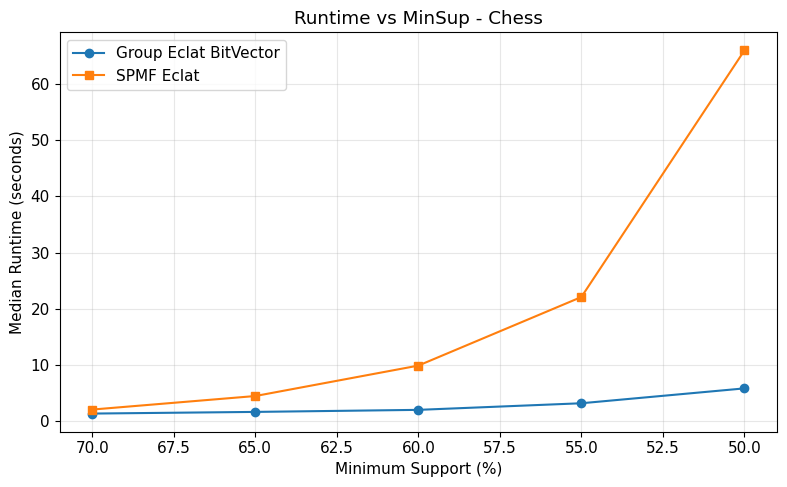

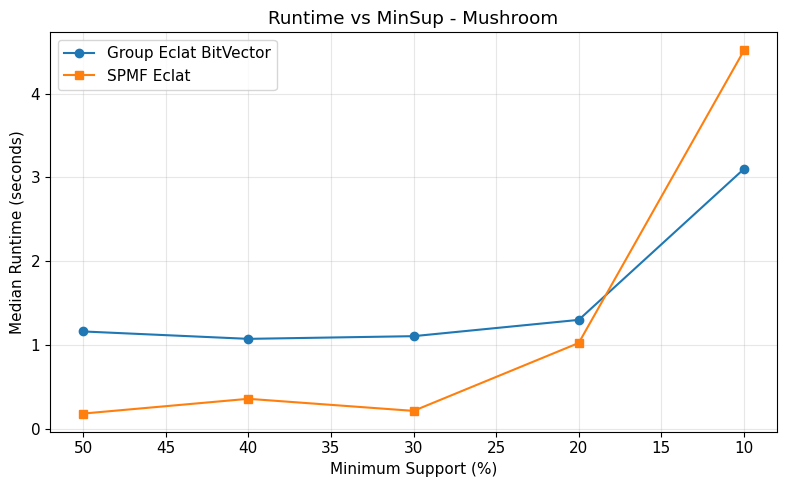

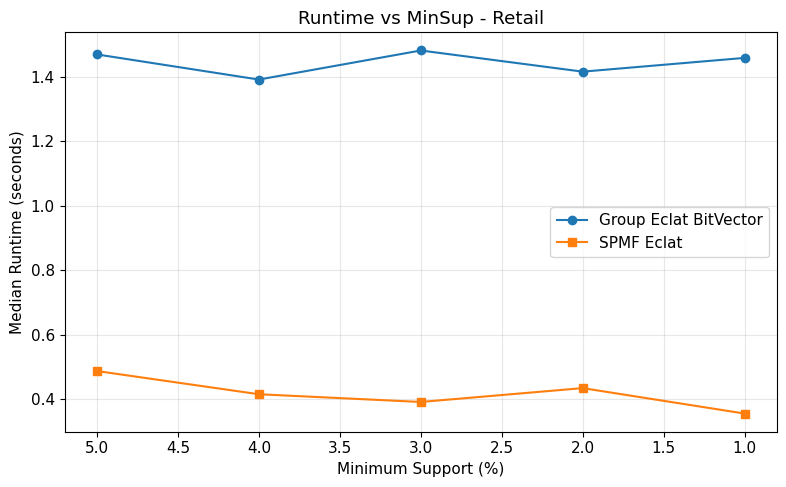

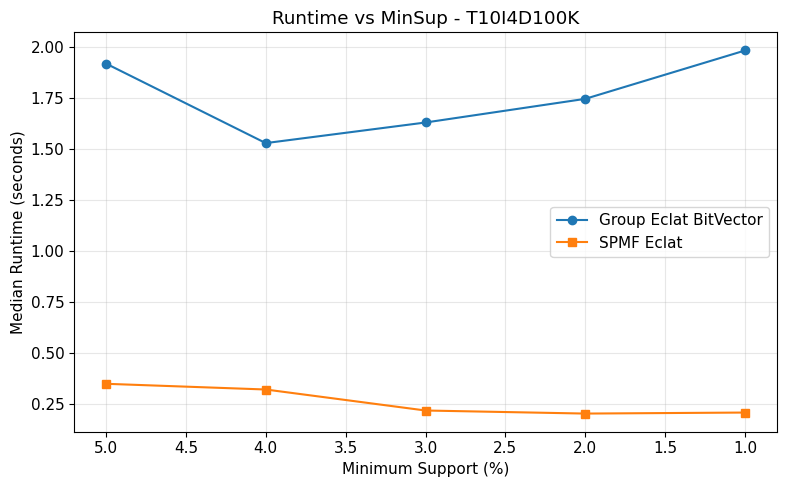

## Frequent Itemset Count

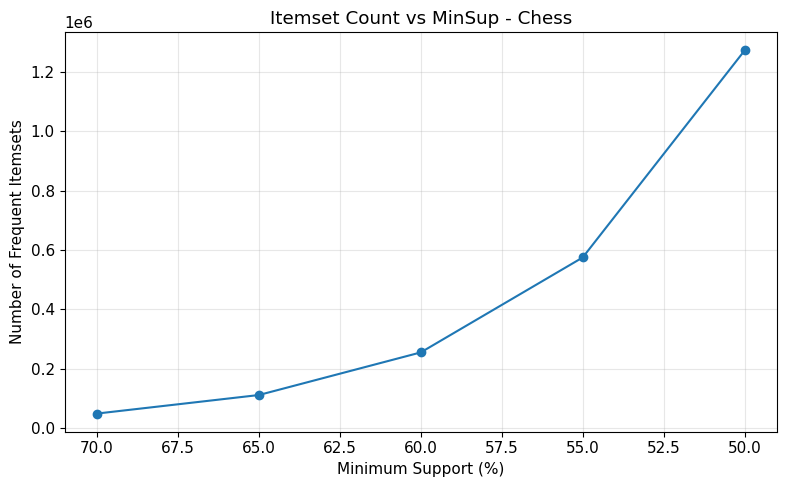

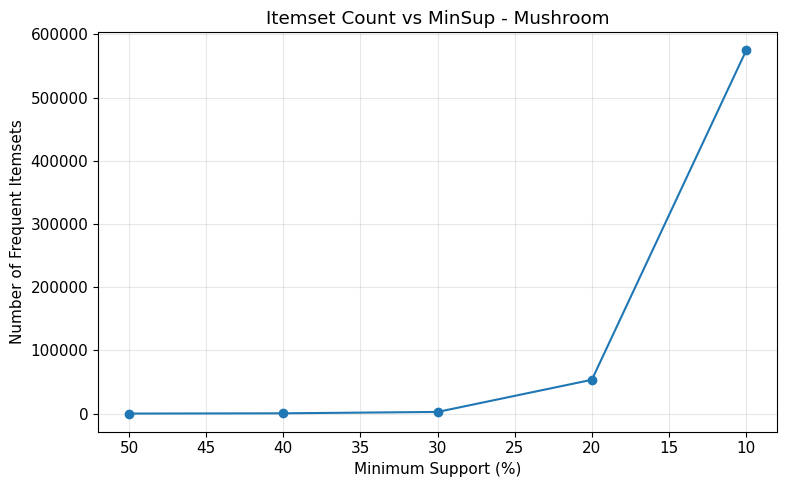

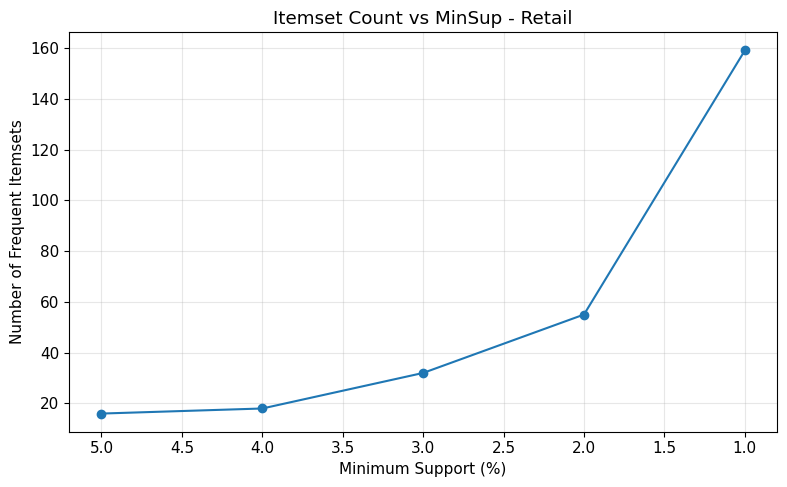

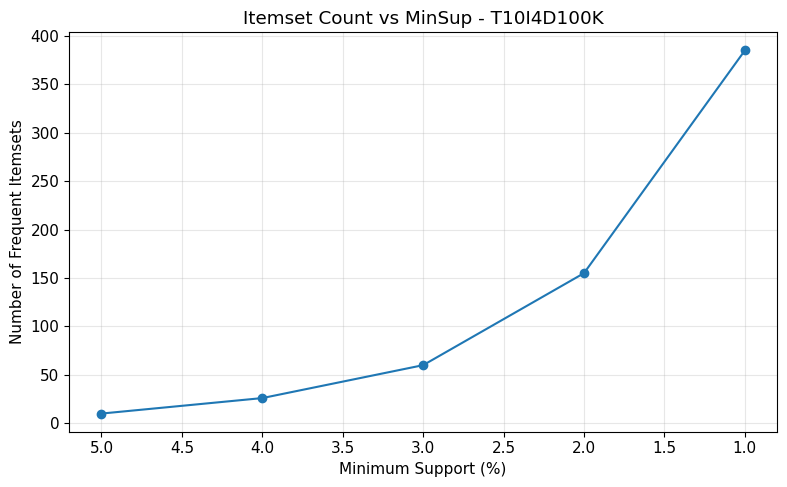

## Peak Memory Comparison

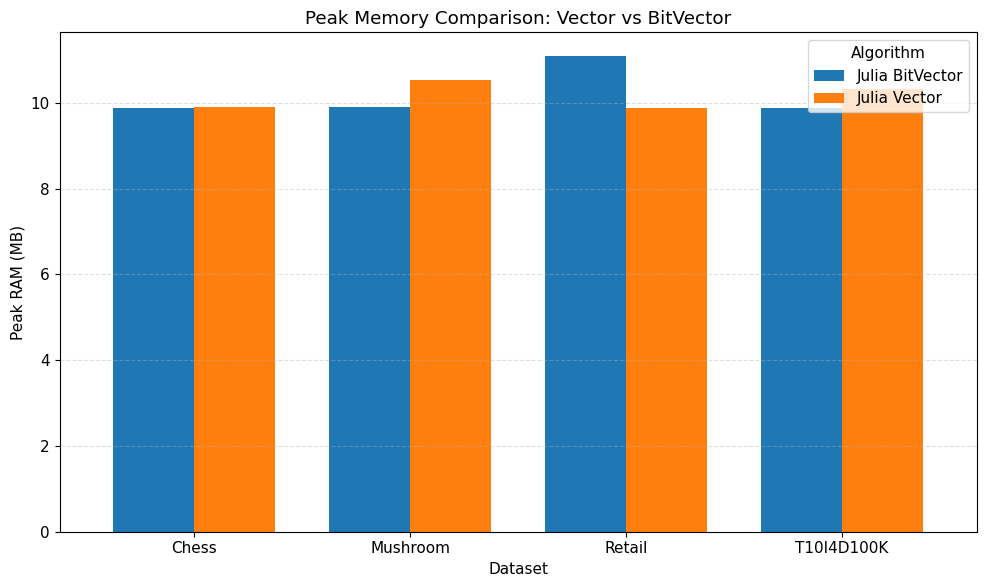

## Scalability Analysis

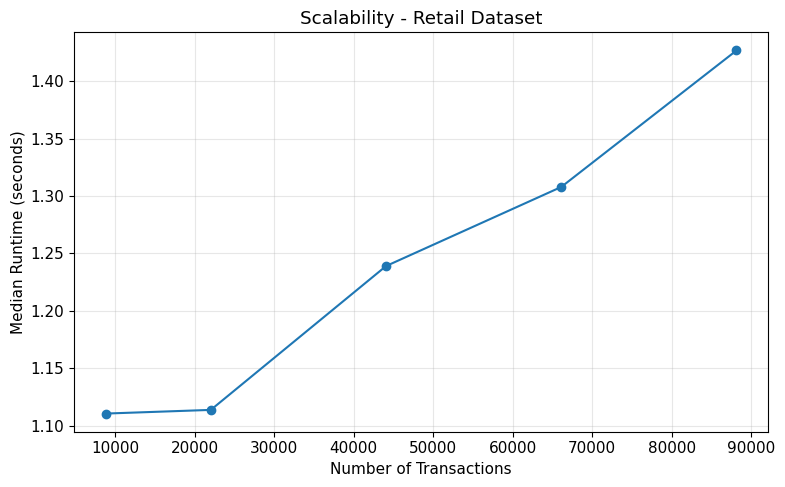

## Impact of Average Transaction Length

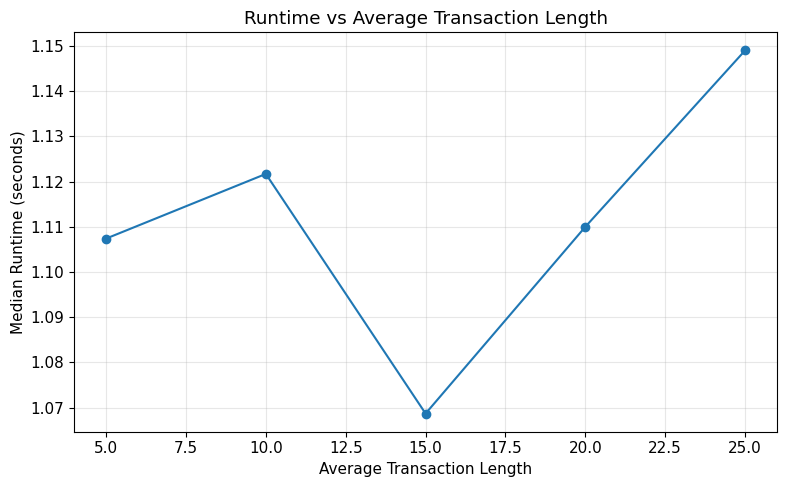


All required figures saved in: /content/Eclat-Frequent-Itemset-Mining/Group_5/docs/figures


In [39]:
# PLOT CONFIGURATION

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()
# 1. RUNTIME: GROUP VS SPMF

display(Markdown("## Runtime Comparison"))

for dataset in datasets:
    group_data = runtime_julia[
        runtime_julia["DatasetKey"] == dataset
    ].sort_values("MinsupPercent", ascending=False)

    spmf_data = runtime_spmf[
        runtime_spmf["DatasetKey"] == dataset
    ].sort_values("MinsupPercent", ascending=False)

    if group_data.empty or spmf_data.empty:
        print(f"Missing runtime data: {dataset}")
        continue

    plt.figure()

    plt.plot(
        group_data["MinsupPercent"],
        group_data["MedianSec"],
        marker="o",
        label="Group Eclat BitVector"
    )

    plt.plot(
        spmf_data["MinsupPercent"],
        spmf_data["MedianSec"],
        marker="s",
        label="SPMF Eclat"
    )

    plt.xlabel("Minimum Support (%)")
    plt.ylabel("Median Runtime (seconds)")
    plt.title(f"Runtime vs MinSup - {dataset_labels[dataset]}")
    plt.gca().invert_xaxis()
    plt.legend()
    plt.grid(True, alpha=0.3)

    save_plot(f"runtime_{dataset}.png")

# 2. FREQUENT ITEMSET COUNT

display(Markdown("## Frequent Itemset Count"))

itemset_count["DatasetKey"] = (
    itemset_count["Dataset"].apply(dataset_key)
)

for dataset in datasets:
    data = itemset_count[
        itemset_count["DatasetKey"] == dataset
    ].sort_values("MinsupPercent", ascending=False)

    if data.empty:
        print(f"Missing itemset data: {dataset}")
        continue

    plt.figure()

    plt.plot(
        data["MinsupPercent"],
        data["ItemsetCount"],
        marker="o"
    )

    plt.xlabel("Minimum Support (%)")
    plt.ylabel("Number of Frequent Itemsets")
    plt.title(f"Itemset Count vs MinSup - {dataset_labels[dataset]}")
    plt.gca().invert_xaxis()
    plt.grid(True, alpha=0.3)

    save_plot(f"itemset_count_{dataset}.png")

# 3. PEAK MEMORY: VECTOR VS BITVECTOR

display(Markdown("## Peak Memory Comparison"))
memory_plot = memory.pivot_table(
    index="Dataset",
    columns="Algorithm",
    values="MaxPeakRAM_MB",
    aggfunc="first"
)

dataset_order = ["chess", "mushroom", "retail", "t10i4d100k"]
memory_plot.index = memory_plot.index.str.strip().str.lower()
memory_plot = memory_plot.reindex(dataset_order)

ax = memory_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Peak Memory Comparison: Vector vs BitVector")
ax.set_xlabel("Dataset")
ax.set_ylabel("Peak RAM (MB)")
ax.set_xticklabels(
    ["Chess", "Mushroom", "Retail", "T10I4D100K"],
    rotation=0
)
ax.legend(title="Algorithm")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(
    FIGURES_DIR / "peak_memory_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# 4. SCALABILITY

display(Markdown("## Scalability Analysis"))

scalability = scalability.sort_values("Transactions")

plt.figure()

plt.plot(
    scalability["Transactions"],
    scalability["MedianSec"],
    marker="o"
)

plt.xlabel("Number of Transactions")
plt.ylabel("Median Runtime (seconds)")
plt.title("Scalability - Retail Dataset")
plt.grid(True, alpha=0.3)

save_plot("scalability_retail.png")

# 5. TRANSACTION LENGTH

display(Markdown("## Impact of Average Transaction Length"))

transaction_length = transaction_length.sort_values(
    "AvgTransactionLength"
)

plt.figure()

plt.plot(
    transaction_length["AvgTransactionLength"],
    transaction_length["MedianSec"],
    marker="o"
)

plt.xlabel("Average Transaction Length")
plt.ylabel("Median Runtime (seconds)")
plt.title("Runtime vs Average Transaction Length")
plt.grid(True, alpha=0.3)

save_plot("transaction_length_runtime.png")

print("\nAll required figures saved in:", FIGURES_DIR)


# 6. Application 1: Market Basket Analysis


## 6.1. Problem Description

This application demonstrates the use of the Eclat algorithm
for mining frequent itemsets from retail transaction data.

Each transaction represents a customer's purchase, and each
item represents a product identifier.

The objective is to discover frequently co-occurring products
and generate association rules to identify purchasing patterns.


## 6.2. Dataset and Preprocessing

The retail dataset contains customer transactions represented
as sets of integer item IDs.

- Dataset: Retail transaction database.
- Transaction: One customer transaction.
- Item: One product identifier.
Using the Rule of Thumb, we chose the minium support and minium confidence as:
- Minimum support: 0.5%.
- Minimum confidence: 0.60.

The dataset is converted into a vertical database structure
using the BitVector representation.


In [40]:
from pathlib import Path

RETAIL_FILE = PROJECT_ROOT / "data" / "benchmark" / "retail.txt"

assert RETAIL_FILE.exists(), f"Missing dataset: {RETAIL_FILE}"

with open(RETAIL_FILE, "r") as f:
    retail_transactions = [
        line.strip().split()
        for line in f
        if line.strip()
    ]

print("Dataset:", RETAIL_FILE.name)
print("Number of transactions:", len(retail_transactions))
print(
    "Number of unique items:",
    len(set(item for transaction in retail_transactions for item in transaction))
)
print(
    "Average transaction length:",
    round(
        sum(len(t) for t in retail_transactions)
        / len(retail_transactions),
        2
    )
)

Dataset: retail.txt
Number of transactions: 88162
Number of unique items: 16470
Average transaction length: 10.31



## 6.3. Frequent Itemset and Association Rule Mining

The Eclat BitVector algorithm is applied to discover frequent
itemsets from the retail transaction database.

Association rules are subsequently generated using a minimum
confidence threshold.

The Lift metric is used to evaluate the strength of associations
between products.


In [41]:
import subprocess

result_app1 = subprocess.run(
    ["julia", "tests/run_application1.jl"],
    cwd=str(PROJECT_ROOT),
    capture_output=True,
    text=True
)

print(result_app1.stdout)

if result_app1.returncode != 0:
    print(result_app1.stderr)
    raise RuntimeError("Application 1 failed.")


APPLICATION 1: Market Basket Analysis
Dataset: Retail
Transactions: 88162
MinSup (%): 0.5
MinSup count: 441
MinConf: 0.6
Frequent itemsets: 580
Association rules: 329

Top 10 Association Rules by Lift:
--------------------------------------------------
1. (16011,) => (16010,) | Support = 0.0074 | Confidence = 0.9731 | Lift = 65.1899
2. (39, 286) => (38, 48) | Support = 0.0052 | Confidence = 0.6107 | Lift = 6.7771
3. (36, 41) => (38, 39) | Support = 0.0063 | Confidence = 0.79 | Lift = 6.7325
4. (41, 170) => (38, 48) | Support = 0.0055 | Confidence = 0.6012 | Lift = 6.6725
5. (48, 286) => (38, 39) | Support = 0.0052 | Confidence = 0.775 | Lift = 6.6043
6. (48, 170) => (38, 39) | Support = 0.0135 | Confidence = 0.7662 | Lift = 6.5298
7. (41, 170) => (38, 39) | Support = 0.007 | Confidence = 0.764 | Lift = 6.5107
8. (36, 48) => (38, 39) | Support = 0.0123 | Confidence = 0.7627 | Lift = 6.5
9. (41, 110) => (38, 39) | Support = 0.0058 | Confidence = 0.7548 | Lift = 6.4325
10. (48, 110) => (

In [47]:
import os
import pandas as pd
from IPython.display import display

print("\n=== frequent_itemsets.csv ===")
df = pd.read_csv("./results/application1/frequent_itemsets.csv")
print("Count:", len(df))
display(df.head(10))

print("\n=== association_rules.csv and Top 10 Association Rules ===")
df = pd.read_csv("./results/application1/association_rules.csv")
print("Count:", len(df))
display(df.head(10))


=== frequent_itemsets.csv ===
Count: 580


,Itemset,SupportCount,Support
0,2,549,0.006227
1,9,1372,0.015562
2,9 39,832,0.009437
3,9 39 48,546,0.006193
4,9 48,790,0.008961
5,10,712,0.008076
6,10 39,452,0.005127
7,11,711,0.008065
8,11 39,472,0.005354
9,11 48,463,0.005252



=== association_rules.csv and Top 10 Association Rules ===
Count: 329


,Antecedent,Consequent,SupportCount,Support,Confidence,Lift
0,16011,16010,651,0.007384,0.973094,65.189915
1,39 286,38 48,458,0.005195,0.610667,6.777139
2,36 41,38 39,553,0.006273,0.790000,6.732526
3,41 170,38 48,484,0.005490,0.601242,6.672548
4,48 286,38 39,458,0.005195,0.774958,6.604333
5,48 170,38 39,1193,0.013532,0.766217,6.529843
6,41 170,38 39,615,0.006976,0.763975,6.510737
7,36 48,38 39,1080,0.012250,0.762712,6.499971
8,41 110,38 39,511,0.005796,0.754801,6.432550
9,48 110,38 39,1031,0.011694,0.747101,6.366936



## 6.4. Conclusion

The experiment demonstrates how frequent itemset mining can
identify products that frequently appear together in retail
transactions.

Association rules provide additional insights into purchasing
behavior.

- Support measures how frequently an itemset appears in the dataset.
- Confidence measures the reliability of an association rule.
- Lift measures how strongly two itemsets are associated compared
  with their independent occurrence.

A Lift greater than 1 indicates a positive association between
the antecedent and consequent.

These results, especially association rules with high lift, can support product recommendation, cross-selling,
and retail product placement strategies.


# 7. Application 2: Protein Sequence Mining



## 7.1. Problem Description

The objective of this application is to discover frequent sequence acid amin patterns in a collection of protein sequences using the Eclat Frequent Itemset Mining algorithm.



## 7.2. Dataset Description

The experimented dataset consists of protein sequences of human with different functions collected for this application. Each protein sequence is treated as one transaction.

The dataset is represented using three files:

| File | Description |
|---|---|
| `protein_transactions.txt` | Transaction database containing item IDs |
| `kmer_mapping.csv` | Mapping between item IDs and 3-mer sequences |
| `protein_metadata.csv` | Mapping between transaction IDs and protein accessions |

A transaction contains the distinct 3-mers found in one protein sequence. The original sequence information is retained through the mapping and metadata files to support biological interpretation after mining.

## 7.3. Data Preprocessing

The original protein sequences are transformed into a transaction database through the following preprocessing steps using `preprocess_application2.jl`.

### Step 1: Sequence Cleaning
Protein sequences are normalized by removing FASTA headers and whitespace, and converting sequence characters to uppercase. Invalid or non-standard amino acid symbols are handled consistently before k-mer generation.

### Step 2: K-mer Generation
A sliding window of length \(k=3\) is applied to each protein sequence to generate overlapping 3-mers.

For a sequence of length \(L\), the number of generated 3-mer windows is:

\[
L-k+1=L-2
\]

### Step 3: Transaction Construction
Each protein sequence is represented as one transaction. Repeated occurrences of the same 3-mer within a protein are treated as a single item, because the transaction records item presence rather than occurrence frequency.

### Step 4: Item ID Encoding
Each distinct 3-mer is assigned a unique integer ItemID. The mapping is stored in `kmer_mapping.csv`.

### Step 5: Transaction and Metadata Export
The encoded transactions are written to `protein_transactions.txt`. Protein accessions and transaction IDs are stored in `protein_metadata.csv`.

The resulting transaction database is suitable for frequent itemset mining using Eclat.

In [48]:
from pathlib import Path
import pandas as pd
from collections import Counter

DATA_DIR = PROJECT_ROOT / "data" / "application2"

transaction_file = DATA_DIR / "protein_transactions.txt"
mapping_file = DATA_DIR / "kmer_mapping.csv"
metadata_file = DATA_DIR / "protein_metadata.csv"

# Load transaction database
with open(transaction_file, "r", encoding="utf-8") as f:
    transactions = [
        line.strip().split()
        for line in f
        if line.strip()
    ]

# Load mapping and metadata
kmer_mapping = pd.read_csv(mapping_file)
protein_metadata = pd.read_csv(metadata_file)

# Basic dataset statistics
num_transactions = len(transactions)
items_per_transaction = [len(set(t)) for t in transactions]
all_items = set(item for t in transactions for item in t)

print("PREPROCESSING VALIDATION")
print("Number of transactions:", num_transactions)
print("Number of unique ItemIDs:", len(all_items))
print("Average unique 3-mers per protein:",
      sum(items_per_transaction) / num_transactions)
print("Minimum unique 3-mers:", min(items_per_transaction))
print("Maximum unique 3-mers:", max(items_per_transaction))

print("\nK-mer mapping shape:", kmer_mapping.shape)
display(kmer_mapping.head())

print("\nProtein metadata shape:", protein_metadata.shape)
display(protein_metadata.head())

PREPROCESSING VALIDATION
Number of transactions: 20
Number of unique ItemIDs: 4216
Average unique 3-mers per protein: 349.85
Minimum unique 3-mers: 102
Maximum unique 3-mers: 1193

K-mer mapping shape: (4216, 2)


,ItemID,Kmer
0,1,AAA
1,2,AAC
2,3,AAD
3,4,AAE
4,5,AAF



Protein metadata shape: (20, 5)


,TransactionID,Accession,Organism,SequenceLength,UniqueKmerCount
0,1,P00441,Homo sapiens,154,149
1,2,P00797,Homo sapiens,406,384
2,3,P01034,Homo sapiens,146,141
3,4,P01308,Homo sapiens,110,102
4,5,P01579,Homo sapiens,166,164


In [49]:
# Check for duplicate items within each transaction
duplicate_transactions = sum(
    len(t) != len(set(t))
    for t in transactions
)

# Check whether every transaction item has a mapping
mapping_item_ids = set(
    kmer_mapping.iloc[:, 0].astype(str)
)

unmapped_items = all_items - mapping_item_ids

print("Transactions with duplicate items:", duplicate_transactions)
print("Items without k-mer mapping:", len(unmapped_items))

if unmapped_items:
    print("Examples:", list(unmapped_items)[:10])

Transactions with duplicate items: 0
Items without k-mer mapping: 0


## 7.4. Data Representation

After preprocessing, the protein dataset is represented as a transaction database:

**D = {T1, T2, ..., Tn}**

where each transaction Ti represents one protein and contains the distinct 3-mer items found in that sequence.

For example, a protein sequence containing the 3-mers `MKT`, `KTA`, `TAL`, and `MKT` is represented as:

**Ti = {MKT, KTA, TAL}**

The repeated 3-mer `MKT` is included only once in the transaction.

The dataset is then converted into a vertical representation. Each item is associated with a BitVector indicating the transactions in which it appears.

The support of an itemset is calculated by performing a bitwise AND operation on the BitVectors of its items and counting the set bits.

## 7.5. Mining Algorithm and Parameters

The Eclat BitVector algorithm is applied to the preprocessed protein transaction database.

The following parameters are used:

| Parameter | Value |
|---|---|
| Algorithm | Eclat BitVector |
| Dataset | Protein sequences |
| Number of transactions | 20 |
| K-mer length | 3 |
| Minimum support thresholds | 20%, 25%, 30%, 35%, 40% |



In [50]:
import subprocess

result = subprocess.run(
    ["julia", "--project=.", "tests/run_application2.jl"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Application 2 mining failed.")

=== APPLICATION 2: PROTEIN MINING ===
Input: /content/Eclat-Frequent-Itemset-Mining/Group_5/data/application2/protein_transactions.txt
Algorithm: BitVector
MinSup values: [20, 25, 30, 35, 40]

----------------------------------------
Running Eclat with MinSup = 20%
Output: /content/Eclat-Frequent-Itemset-Mining/Group_5/data/application2/frequent_itemsets_minsup20.txt
Mining completed successfully!
Algorithm: bitvector
Transactions: 20
Minimum support (%): 20.0
Minimum support count: 4
Frequent itemsets: 673
Output file: /content/Eclat-Frequent-Itemset-Mining/Group_5/data/application2/frequent_itemsets_minsup20.txt
Completed MinSup = 20%

----------------------------------------
Running Eclat with MinSup = 25%
Output: /content/Eclat-Frequent-Itemset-Mining/Group_5/data/application2/frequent_itemsets_minsup25.txt
Mining completed successfully!
Algorithm: bitvector
Transactions: 20
Minimum support (%): 25.0
Minimum support count: 5
Frequent itemsets: 82
Output file: /content/Eclat-Frequen

## 7.6. Frequent Itemset Statistics

The number of frequent itemsets is analyzed at different minimum support thresholds. This experiment demonstrates how the support threshold affects the number and characteristics of discovered patterns.

The analysis includes:
- Total number of frequent itemsets for each MinSup.
- Distribution of frequent itemsets by itemset length.
- Frequent patterns with the highest support.

In [51]:
result = subprocess.run(
    ["julia", "--project=.", "tests/analyze_application2.jl"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Application 2 analysis failed.")

=== APPLICATION 2: PROTEIN ANALYSIS ===
Transactions: 20
K-mer mappings: 4216
Protein metadata: 20
MinSup values: [20, 25, 30, 35, 40]


========== MinSup 20% ==========

MINIMUM SUPPORT: 20%
Total frequent itemsets: 673

Itemsets by length:
Length 1: 222
Length 2: 218
Length 3: 128
Length 4: 67
Length 5: 29
Length 6: 8
Length 7: 1

Itemsets by support:
Support 4: 591
Support 5: 56
Support 6: 24
Support 7: 2

Top 10 itemsets by support:
1690 | Support: 7 | Length: 1
796 | Support: 7 | Length: 1
1 | Support: 6 | Length: 1
124 | Support: 6 | Length: 1
1286 | Support: 6 | Length: 1
132 | Support: 6 | Length: 1
1788 | Support: 6 | Length: 1
1853 | Support: 6 | Length: 1
2004 | Support: 6 | Length: 1
2010 | Support: 6 | Length: 1

Biological analysis - MinSup = 20%
Itemsets exported: 673
Support mismatches: 0
Output: /content/Eclat-Frequent-Itemset-Mining/Group_5/results/application2/biological_itemsets_minsup20.csv


========== MinSup 25% ==========

MINIMUM SUPPORT: 25%
Total frequent ite

In [ ]:
RESULT_DIR = PROJECT_ROOT / "results" / "application2"

for minsup in [20, 25, 30, 35]:
    file_path = (
        RESULT_DIR /
        f"biological_itemsets_minsup{minsup}.csv"
    )

    print(f"\n=== MinSup {minsup}% ===")

    if file_path.exists():
        df = pd.read_csv(file_path)
        display(df.head(10))
    else:
        print("File not found:", file_path)

## 7.8. Results and Discussion

The mining results show that the number of frequent itemsets decreases as the minimum support threshold increases.

At lower MinSup values, the algorithm discovers more patterns, including patterns that occur in a smaller subset of proteins. At higher MinSup values, only patterns shared by a larger proportion of the protein transactions remain frequent.

The biological analysis provides the k-mer combinations and protein accessions associated with the discovered patterns. This information helps interpret the frequent itemsets in the context of protein sequence data.

The results demonstrate that Eclat BitVector can be applied to protein sequence mining by transforming sequences into transactions and using vertical BitVector intersections to calculate itemset support.

## 7.9. Conclusion

This application demonstrates the use of Eclat BitVector for frequent pattern mining in protein sequences.

The preprocessing stage converts each protein into a transaction of distinct 3-mers and assigns integer IDs to the k-mers. The mining stage discovers frequent itemsets under different support thresholds, while the biological analysis maps the resulting patterns back to k-mer sequences and protein accessions.

The application illustrates how frequent itemset mining can be used to explore recurring sequence patterns in biological data. Further biological validation is necessary before drawing conclusions about protein function or relationships.